# Phase II: Data Wrangling and EDA
## Inclusive Growth Score (IGS): Louisiana Census Tracts

**Student:** Shema Ntivuguruzwa|  **Region:** Louisiana  |  **Data:** Mastercard Inclusive Growth Score reports (v3.0, year 2025)

**What this notebook does**
1. Loads the IGS data for 4 sample tracts (typed in from the PDF reports)
2. Cleans it (missing values, non-residential tracts, benchmark check)
3. Makes 7 charts to explore the data
4. Writes down the main findings and the next steps

Four tracts is a very small sample. This notebook is built so that the same code works when more tracts are added.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 2. Load the data

The reports are PDFs, so the numbers are typed in below. Each tract has:
- a **headline table** (population, income, overall score, pillar scores)
- **18 metrics** (6 per pillar). Each metric has the tract value, the benchmark value, and a score from 0 to 100 (a percentile).

`None` means the report showed "—" or "No Data".

In [2]:
# ---------- Headline data (one row per tract) ----------
# avg_* = "Pillar Average" row; place_*, econ_*, comm_* = pillar rows (inc = inclusion, gro = growth)
tracts = pd.DataFrame([
    dict(tract_id="22005030900", label="Ascension", parish="Ascension", pop=4827, median_income=36369,
         metro_code="2 Metro", benchmark="USA", igs=28, igs_change=np.nan,
         avg_inc=26, avg_gro=29, avg_score=28,
         place_inc=36, place_gro=28, place_score=32,
         econ_inc=8,  econ_gro=45, econ_score=27, econ_change=4,
         comm_inc=34, comm_gro=14, comm_score=24, comm_change=-4),
    dict(tract_id="22111960500", label="Union", parish="Union", pop=4234, median_income=54778,
         metro_code="3 Metro", benchmark="Urban-Rural", igs=54, igs_change=2,
         avg_inc=49, avg_gro=60, avg_score=54,
         place_inc=50, place_gro=47, place_score=48,
         econ_inc=36, econ_gro=66, econ_score=51, econ_change=8,
         comm_inc=61, comm_gro=69, comm_score=65, comm_change=np.nan),
    dict(tract_id="22015011117", label="Bossier", parish="Bossier", pop=np.nan, median_income=np.nan,
         metro_code=None, benchmark="Urban-Rural", igs=56, igs_change=4,
         avg_inc=45, avg_gro=66, avg_score=56,
         place_inc=39, place_gro=52, place_score=46,
         econ_inc=58, econ_gro=58, econ_score=58, econ_change=7,
         comm_inc=39, comm_gro=89, comm_score=64, comm_change=4),
    dict(tract_id="22013970500", label="Bienville", parish="Bienville", pop=2505, median_income=27925,
         metro_code="6 Nonmetro", benchmark="Urban-Rural", igs=32, igs_change=6,
         avg_inc=27, avg_gro=37, avg_score=32,
         place_inc=12, place_gro=26, place_score=19,
         econ_inc=40, econ_gro=54, econ_score=47, econ_change=18,
         comm_inc=28, comm_gro=30, comm_score=29, comm_change=np.nan),
])
tracts

,tract_id,label,parish,pop,median_income,metro_code,benchmark,igs,igs_change,avg_inc,avg_gro,avg_score,place_inc,place_gro,place_score,econ_inc,econ_gro,econ_score,econ_change,comm_inc,comm_gro,comm_score,comm_change
0,22005030900,Ascension,Ascension,4827.0,36369.0,2 Metro,USA,28,NaN,26,29,28,36,28,32,8,45,27,4,34,14,24,-4.0
1,22111960500,Union,Union,4234.0,54778.0,3 Metro,Urban-Rural,54,2.0,49,60,54,50,47,48,36,66,51,8,61,69,65,NaN
2,22015011117,Bossier,Bossier,NaN,NaN,None,Urban-Rural,56,4.0,45,66,56,39,52,46,58,58,58,7,39,89,64,4.0
3,22013970500,Bienville,Bienville,2505.0,27925.0,6 Nonmetro,Urban-Rural,32,6.0,27,37,32,12,26,19,40,54,47,18,28,30,29,NaN


In [3]:
# ---------- Metric data (long format: one row per tract x metric) ----------
A, U, B, Bi = "Ascension", "Union", "Bossier", "Bienville"
N = (None, None, None)

# (pillar, metric, type, {tract: (tract_value, benchmark_value, score)})
metric_defs = [
    ("Place", "Net Occupancy", "Growth", {A:(-18.6,-0.7,28), U:(-7.8,-1.3,41), B:(-44.0,-0.7,34), Bi:(-10.1,-1.7,25)}),
    ("Place", "Residential Real Estate Value", "Growth", {A:(14.9,40.7,28), U:(30.9,33.3,53), B:(47.9,38.3,70), Bi:(-16.4,29.3,26)}),
    ("Place", "Acres of Park Land", "Inclusion", {A:(0.0,3.5,4), U:(7.9,2.7,77), B:(0.1,3.1,8), Bi:(1.1,1.5,45)}),
    ("Place", "Affordable Housing", "Inclusion", {A:(88.3,75.9,94), U:(89.0,79.7,92), B:(77.1,77.1,50), Bi:(66.1,82.3,2)}),
    ("Place", "Internet Access", "Inclusion", {A:(68.4,89.1,4), U:(81.2,86.7,27), B:(78.1,88.9,14), Bi:(58.3,81.7,2)}),
    ("Place", "Travel Time to Work", "Inclusion", {A:(61.0,63.8,44), U:(46.0,76.8,5), B:(84.8,72.5,84), Bi:(33.6,65.6,1)}),

    ("Economy", "New Businesses", "Growth", {A:(8.3,7.5,48), U:(38.9,5.0,70), B:(13.8,7.1,75), Bi:(28.6,2.3,65)}),
    ("Economy", "Spend Growth", "Growth", {A:(None,None,41), U:N, B:(None,None,37), Bi:N}),
    ("Economy", "Small Business Loans", "Growth", {A:(0.0,0.0,47), U:(0.0,0.0,62), B:(0.0,0.0,63), Bi:(0.0,0.0,43)}),
    ("Economy", "Minority/Women Owned Businesses", "Inclusion", {A:(0.0,0.0,0), U:(0.1,0.1,1), B:(1.7,2.4,34), Bi:(5.6,2.9,84)}),
    ("Economy", "Labor Market Engagement Index", "Inclusion", {A:(2.0,49.0,2), U:(30.7,41.0,37), B:(49.9,47.0,53), Bi:(16.0,28.0,26)}),
    ("Economy", "Commercial Diversity", "Inclusion", {A:(2.4,4.8,15), U:(3.7,4.8,34), B:(8.9,4.8,87), Bi:(2.2,4.5,10)}),

    ("Community", "Personal Income", "Growth", {A:(2.7,15.7,13), U:(27.9,14.9,69), B:(72.0,15.1,95), Bi:(-3.1,14.4,30)}),
    ("Community", "Spending per Capita", "Growth", {A:(None,None,16), U:N, B:(None,None,83), Bi:N}),
    ("Community", "Female Above Poverty", "Inclusion", {A:(42.0,86.9,2), U:(85.7,85.0,53), B:(83.0,86.3,40), Bi:(78.9,82.9,35)}),
    ("Community", "Gini Coefficient", "Inclusion", {A:(0.6,0.4,3), U:(0.4,0.4,52), B:(0.4,0.4,43), Bi:(0.4,0.4,34)}),
    ("Community", "Early Education Enrollment", "Inclusion", {A:(29.4,24.4,61), U:(25.8,22.9,57), B:(24.2,23.2,53), Bi:(9.2,22.7,13)}),
    ("Community", "Health Insurance Coverage", "Inclusion", {A:(96.4,94.3,69), U:(97.1,93.7,83), B:(88.5,94.1,20), Bi:(88.5,92.2,29)}),
]

rows = []
for pillar, metric, mtype, d in metric_defs:
    for tract, (val, bench, score) in d.items():
        rows.append(dict(pillar=pillar, metric=metric, type=mtype, tract=tract,
                         value=val, benchmark_value=bench, score=score))
metrics_long = pd.DataFrame(rows).astype({"value":"float", "benchmark_value":"float", "score":"float"})
print(metrics_long.shape)
metrics_long.head(8)

(72, 7)


,pillar,metric,type,tract,value,benchmark_value,score
0,Place,Net Occupancy,Growth,Ascension,-18.6,-0.7,28.0
1,Place,Net Occupancy,Growth,Union,-7.8,-1.3,41.0
2,Place,Net Occupancy,Growth,Bossier,-44.0,-0.7,34.0
3,Place,Net Occupancy,Growth,Bienville,-10.1,-1.7,25.0
4,Place,Residential Real Estate Value,Growth,Ascension,14.9,40.7,28.0
5,Place,Residential Real Estate Value,Growth,Union,30.9,33.3,53.0
6,Place,Residential Real Estate Value,Growth,Bossier,47.9,38.3,70.0
7,Place,Residential Real Estate Value,Growth,Bienville,-16.4,29.3,26.0


## 3. Cleaning and data quality checks

Rules used in this project:
1. Drop tracts with **zero population** or a tract code starting with **98** (these are land-use tracts, not neighborhoods).
2. Treat "—" and "No Data" as **missing**, not zero.
3. Check that every tract uses the **same benchmark**.
4. Flag tracts with missing population or income.

In [4]:
# Rule 1: non-residential tracts
def flag_non_residential(df):
    tract_code = df["tract_id"].str[5:]          # last 6 digits = tract code
    return (df["pop"] == 0) | tract_code.str.startswith("98")

# One empty tract was removed before this analysis (kept here as a record)
excluded = pd.DataFrame([{"tract_id": "22051980000", "parish": "Jefferson",
                          "reason": "population 0, median income NaN, tract code 98xxxx"}])
print("Excluded tracts:")
display(excluded)

tracts["non_residential"] = flag_non_residential(tracts)
print("Non-residential tracts in current sample:", int(tracts["non_residential"].sum()))
tracts = tracts[~tracts["non_residential"]].copy()

Excluded tracts:


,tract_id,parish,reason
0,22051980000,Jefferson,"population 0, median income NaN, tract code 98..."


Non-residential tracts in current sample: 0


In [5]:
# Rule 2 and 4: missing values
missing_summary = pd.DataFrame({
    "population_missing": tracts.set_index("label")["pop"].isna(),
    "income_missing": tracts.set_index("label")["median_income"].isna(),
    "metrics_with_no_score": metrics_long[metrics_long["score"].isna()].groupby("tract").size(),
    "metrics_with_no_value": metrics_long[metrics_long["value"].isna()].groupby("tract").size(),
}).fillna(0).astype({"metrics_with_no_score": int, "metrics_with_no_value": int})
missing_summary

,population_missing,income_missing,metrics_with_no_score,metrics_with_no_value
Ascension,False,False,0,2
Bienville,False,False,2,2
Bossier,True,True,0,2
Union,False,False,2,2


In [6]:
# Rule 3: benchmark check
print(tracts[["label", "benchmark"]].to_string(index=False))
if tracts["benchmark"].nunique() > 1:
    print("\nWARNING: tracts use different benchmarks. Scores are percentiles against different groups,")
    print("so they are NOT perfectly comparable. Fix: download all reports with the same benchmark (Urban-Rural).")

# Add a star to labels of tracts that use a different benchmark from the most common one
common_bm = tracts["benchmark"].mode()[0]
tracts["label_plot"] = np.where(tracts["benchmark"] == common_bm, tracts["label"], tracts["label"] + "*")

    label   benchmark
Ascension         USA
    Union Urban-Rural
  Bossier Urban-Rural
Bienville Urban-Rural

so they are NOT perfectly comparable. Fix: download all reports with the same benchmark (Urban-Rural).


In [7]:
# Other quirk: Small Business Loans shows 0.0% for every tract AND for the benchmark, yet the scores differ.
sbl = metrics_long[metrics_long["metric"] == "Small Business Loans"][["tract", "value", "benchmark_value", "score"]]
display(sbl)
print("Same 0.0% value but different scores (43 to 63) -> the displayed value is probably rounded.")
print("Treat this metric as low-information until the raw data is checked.")

,tract,value,benchmark_value,score
32,Ascension,0.0,0.0,47.0
33,Union,0.0,0.0,62.0
34,Bossier,0.0,0.0,63.0
35,Bienville,0.0,0.0,43.0


Same 0.0% value but different scores (43 to 63) -> the displayed value is probably rounded.
Treat this metric as low-information until the raw data is checked.


## 4. Exploratory Data Analysis

**Note on stars (*):** a star after a tract name means it was scored against the USA, not Urban-Rural.

### Chart 1: Overall Inclusive Growth Score by tract

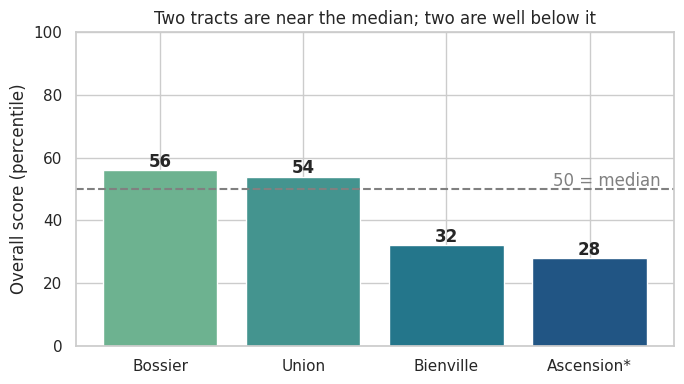

In [8]:
order = tracts.sort_values("igs", ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(order["label_plot"], order["igs"], color=sns.color_palette("crest", len(order)))
ax.axhline(50, ls="--", color="gray")
ax.text(len(order) - 0.5, 51, "50 = median", ha="right", color="gray")
for b, v in zip(bars, order["igs"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, int(v), ha="center", fontweight="bold")
ax.set_ylim(0, 100)
ax.set_ylabel("Overall score (percentile)")
ax.set_title("Two tracts are near the median; two are well below it")
plt.tight_layout()
plt.show()

### Chart 2: Pillar scores by tract

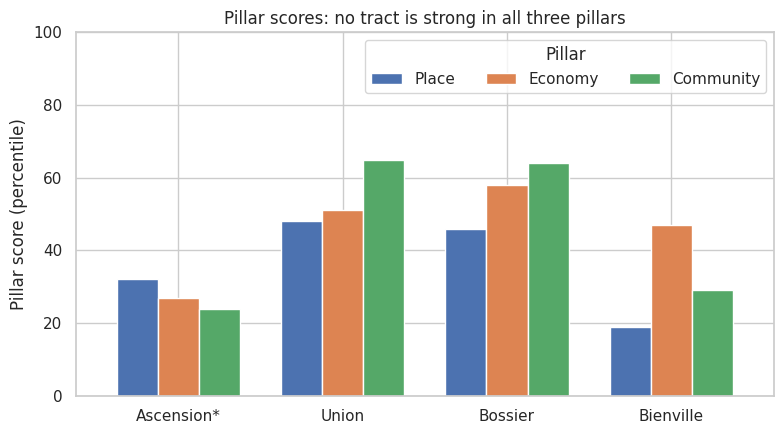

In [9]:
pillar_scores = tracts.set_index("label_plot")[["place_score", "econ_score", "comm_score"]]
pillar_scores.columns = ["Place", "Economy", "Community"]
ax = pillar_scores.plot(kind="bar", figsize=(8, 4.5), rot=0, width=0.75, color=["#4c72b0", "#dd8452", "#55a868"])
ax.set_ylim(0, 100)
ax.set_ylabel("Pillar score (percentile)")
ax.set_xlabel("")
ax.set_title("Pillar scores: no tract is strong in all three pillars")
ax.legend(title="Pillar", loc="upper right", ncol=3)
plt.tight_layout()
plt.show()

### Chart 3: Inclusion vs. Growth (is growth reaching everyone?)

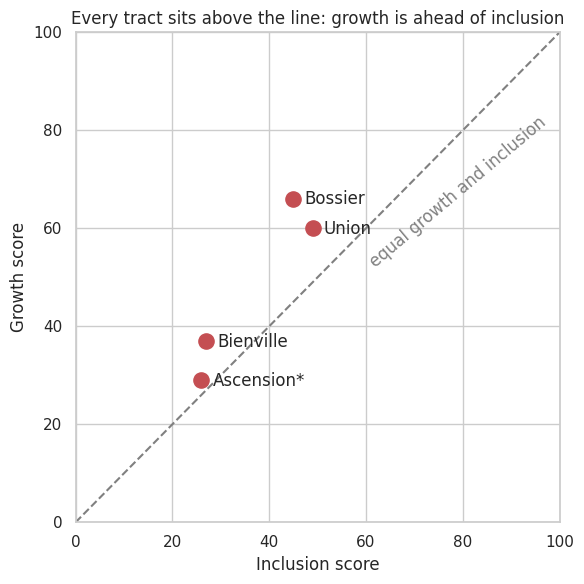

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 100], [0, 100], ls="--", color="gray")
ax.scatter(tracts["avg_inc"], tracts["avg_gro"], s=120, color="#c44e52", zorder=3)
for _, r in tracts.iterrows():
    ax.annotate(r["label_plot"], (r["avg_inc"], r["avg_gro"]), textcoords="offset points", xytext=(8, -4))
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("Inclusion score")
ax.set_ylabel("Growth score")
ax.set_title("Every tract sits above the line: growth is ahead of inclusion")
ax.text(60, 52, "equal growth and inclusion", rotation=40, color="gray")
plt.tight_layout()
plt.show()

### Chart 4: Heatmap of all 18 metric scores

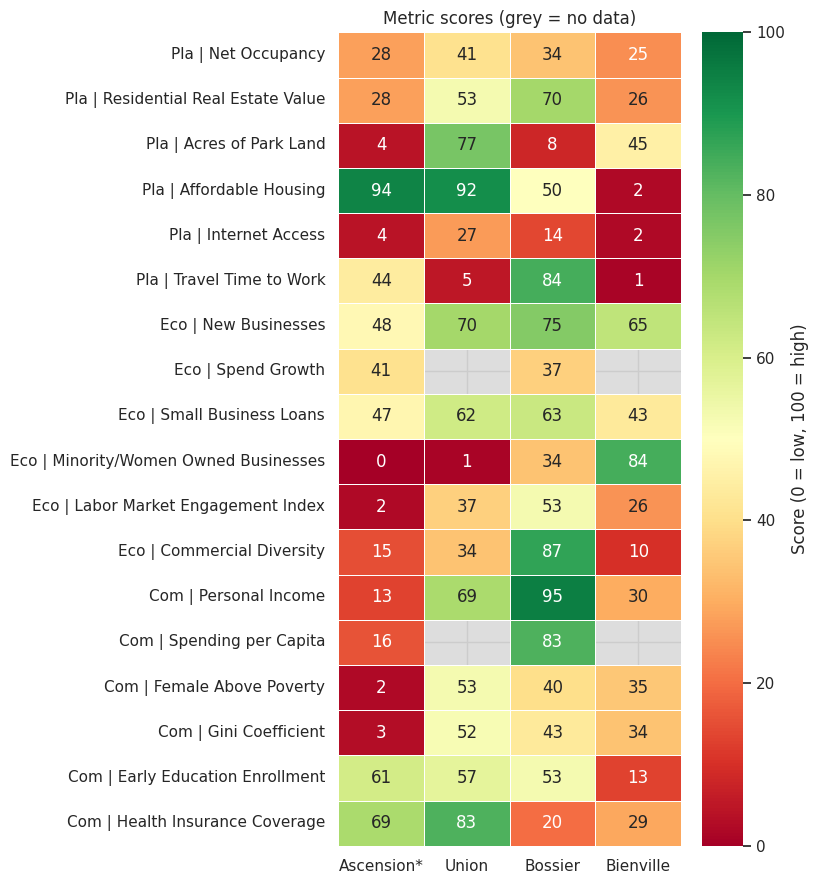

In [11]:
labels = list(tracts["label_plot"])
label_map = dict(zip(tracts["label"], tracts["label_plot"]))
mt = metrics_long[metrics_long["tract"].isin(label_map)].copy()
mt["tract_plot"] = mt["tract"].map(label_map)

row_order = list(dict.fromkeys(zip(mt["pillar"], mt["metric"])))
piv = mt.set_index(["pillar", "metric", "tract_plot"])["score"].unstack("tract_plot")
piv = piv.reindex(pd.MultiIndex.from_tuples(row_order))[labels]
piv.index = [f"{p[:3]} | {m}" for p, m in piv.index]

fig, ax = plt.subplots(figsize=(8, 9))
ax.set_facecolor("#dddddd")   # grey = missing
sns.heatmap(piv, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, center=50,
            linewidths=0.5, cbar_kws={"label": "Score (0 = low, 100 = high)"}, ax=ax)
ax.set_title("Metric scores (grey = no data)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Chart 5: The five lowest-scoring metrics in each tract

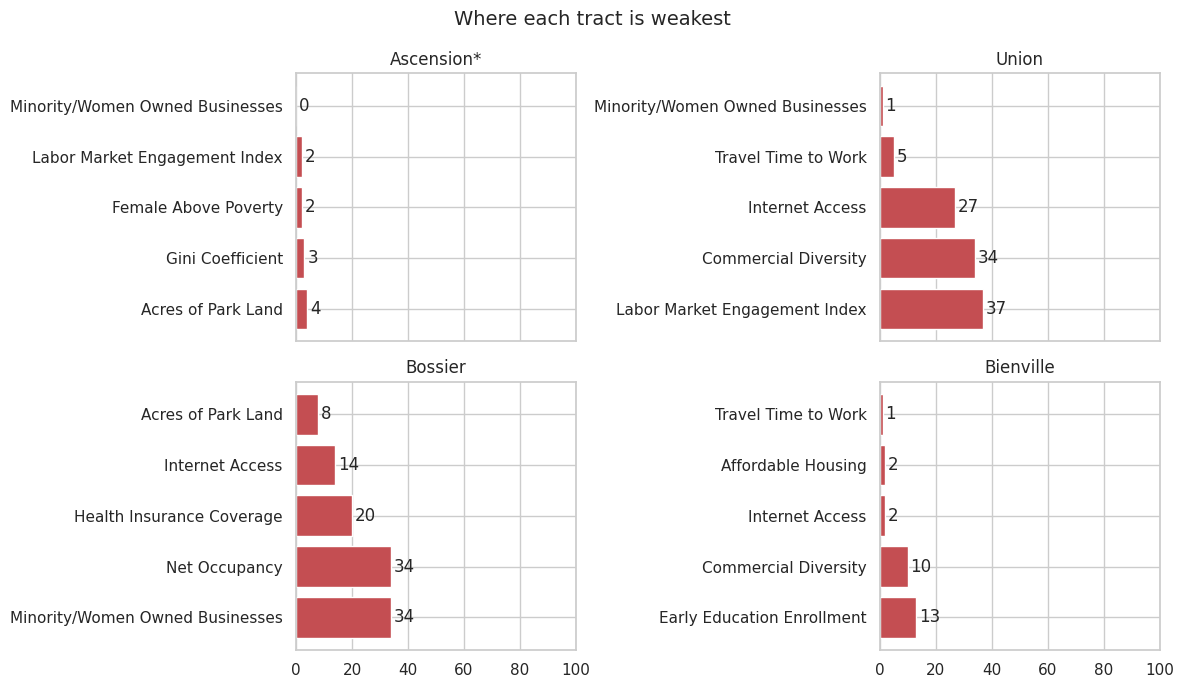

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, lab in zip(axes.ravel(), tracts["label"]):
    d = (mt[mt["tract"] == lab].dropna(subset=["score"]).nsmallest(5, "score")
         .sort_values("score", ascending=False))
    ax.barh(d["metric"], d["score"], color="#c44e52")
    for y, v in enumerate(d["score"]):
        ax.text(v + 1, y, int(v), va="center")
    ax.set_xlim(0, 100)
    ax.set_title(label_map[lab])
fig.suptitle("Where each tract is weakest", fontsize=14)
plt.tight_layout()
plt.show()

### Chart 6: Inclusion minus Growth inside each pillar

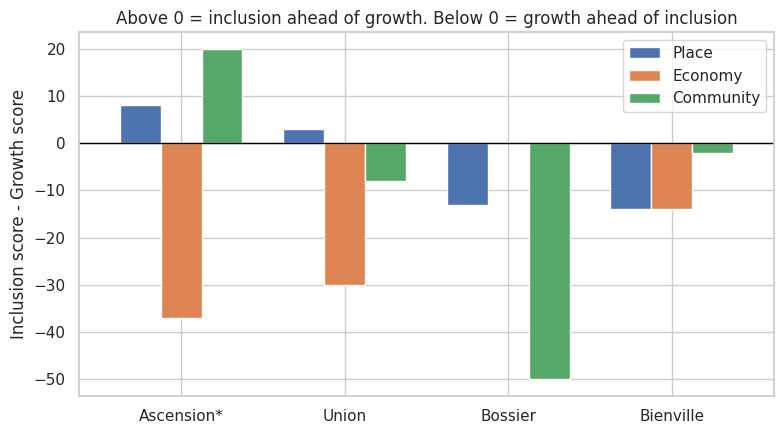

,Place,Economy,Community
label_plot,,,
Ascension*,8,-37,20
Union,3,-30,-8
Bossier,-13,0,-50
Bienville,-14,-14,-2


In [13]:
gap = pd.DataFrame({
    "Place":     tracts["place_inc"] - tracts["place_gro"],
    "Economy":   tracts["econ_inc"]  - tracts["econ_gro"],
    "Community": tracts["comm_inc"]  - tracts["comm_gro"],
})
gap.index = tracts["label_plot"]
ax = gap.plot(kind="bar", figsize=(8, 4.5), rot=0, width=0.75, color=["#4c72b0", "#dd8452", "#55a868"])
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Inclusion score - Growth score")
ax.set_xlabel("")
ax.set_title("Above 0 = inclusion ahead of growth. Below 0 = growth ahead of inclusion")
plt.tight_layout()
plt.show()
gap

### Chart 7: Median income vs. overall score

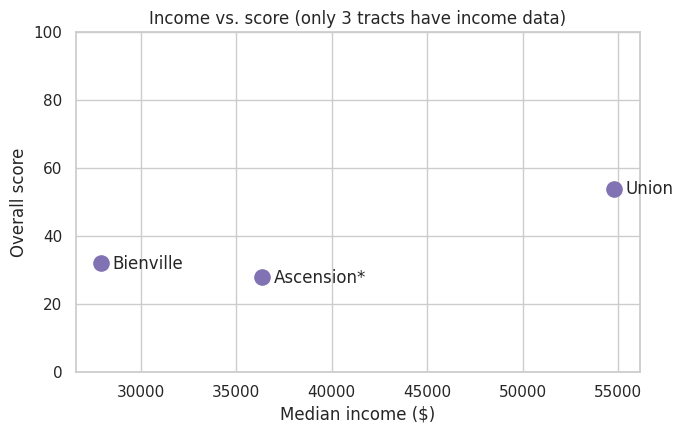

Bossier is left out because its median income is missing.
With 3 points, no correlation can be trusted. This chart is a starting point for when more tracts are added.


In [14]:
has_inc = tracts.dropna(subset=["median_income"])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(has_inc["median_income"], has_inc["igs"], s=120, color="#8172b3")
for _, r in has_inc.iterrows():
    ax.annotate(r["label_plot"], (r["median_income"], r["igs"]), textcoords="offset points", xytext=(8, -4))
ax.set_xlabel("Median income ($)")
ax.set_ylabel("Overall score")
ax.set_ylim(0, 100)
ax.set_title(f"Income vs. score (only {len(has_inc)} tracts have income data)")
plt.tight_layout()
plt.show()
print("Bossier is left out because its median income is missing.")
print("With 3 points, no correlation can be trusted. This chart is a starting point for when more tracts are added.")

## 5. Summary statistics

In [15]:
summary = tracts.set_index("label")[[
    "pop", "median_income", "igs", "avg_inc", "avg_gro",
    "place_score", "econ_score", "comm_score", "econ_change"
]].rename(columns={"avg_inc": "inclusion", "avg_gro": "growth", "econ_change": "econ_change_since_2024"})
summary["growth_minus_inclusion"] = summary["growth"] - summary["inclusion"]
summary

,pop,median_income,igs,inclusion,growth,place_score,econ_score,comm_score,econ_change_since_2024,growth_minus_inclusion
label,,,,,,,,,,
Ascension,4827.0,36369.0,28,26,29,32,27,24,4,3
Union,4234.0,54778.0,54,49,60,48,51,65,8,11
Bossier,NaN,NaN,56,45,66,46,58,64,7,21
Bienville,2505.0,27925.0,32,27,37,19,47,29,18,10


In [16]:
# How many metrics are weak (score < 25) or strong (score >= 75) in each tract?
counts = mt.dropna(subset=["score"]).groupby("tract").agg(
    metrics_scored=("score", "size"),
    weak_below_25=("score", lambda s: int((s < 25).sum())),
    strong_75_plus=("score", lambda s: int((s >= 75).sum())),
    median_metric_score=("score", "median"),
)
counts

,metrics_scored,weak_below_25,strong_75_plus,median_metric_score
tract,,,,
Ascension,18,9,1,22.0
Bienville,16,5,1,27.5
Bossier,18,3,5,51.5
Union,16,2,3,53.0


In [17]:
# Metrics scoring 10 or lower (the most urgent gaps)
urgent = (mt[mt["score"] <= 10][["tract", "pillar", "metric", "value", "benchmark_value", "score"]]
          .sort_values(["tract", "score"]))
urgent

,tract,pillar,metric,value,benchmark_value,score
36,Ascension,Economy,Minority/Women Owned Businesses,0.0,0.0,0.0
40,Ascension,Economy,Labor Market Engagement Index,2.0,49.0,2.0
56,Ascension,Community,Female Above Poverty,42.0,86.9,2.0
60,Ascension,Community,Gini Coefficient,0.6,0.4,3.0
8,Ascension,Place,Acres of Park Land,0.0,3.5,4.0
16,Ascension,Place,Internet Access,68.4,89.1,4.0
23,Bienville,Place,Travel Time to Work,33.6,65.6,1.0
15,Bienville,Place,Affordable Housing,66.1,82.3,2.0
19,Bienville,Place,Internet Access,58.3,81.7,2.0
47,Bienville,Economy,Commercial Diversity,2.2,4.5,10.0


## 6. Findings

4 tracts is a tiny sample, so these are observations to test later, not conclusions

1. Overall scores split into two groups.** Bossier (56) and Union (54) are near the median. Bienville (32) and Ascension (28) are well below it.
2. **Growth is ahead of inclusion in all four tracts** (overall gap of 3, 11, 21 and 10 points for Ascension, Union, Bossier and Bienville). Bossier has the biggest gap.
3. **Ascension has a very low Economy inclusion score (8)** while its Economy growth score is 45. The weak metrics are Minority/Women Owned Businesses (0), Labor Market Engagement (2), and Commercial Diversity (15). Community is also weak: Female Above Poverty scores 2 and the Gini coefficient scores 3. Affordable Housing scores 94, which may reflect low incomes and low home values.
4. **Bienville has the weakest Place pillar (19).** Affordable Housing, Internet Access, and Travel Time to Work score 2, 2 and 1. At the same time, its Economy score rose 18 points since 2024 and Minority/Women Owned Businesses scores 84.
5. **Bossier looks strong on growth but has gaps.** Personal Income growth is 72% (score 95), but Health Insurance (20), Internet Access (14), and Park Land (8) are low. Its population and income are missing, and Net Occupancy fell 44%. This could be a tract-boundary change or a small base. Check this before trusting the 72%.
6. **Union is the most balanced tract.** Its weak spots are Travel Time to Work (5) and Minority/Women Owned Businesses (1).

